In [1]:
!pip install geemap rasterio geopandas shapely folium scikit-image opencv-python-headless -q
from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 25.4 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
import ee
ee.Authenticate()
ee.Initialize(project='aero3-504006')

In [3]:
import ee

aoi = ee.Geometry.Rectangle([77.63, 13.15, 77.78, 13.25])

In [4]:
def get_composite(start, end):
    collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(aoi)
                  .filterDate(start, end)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
                  .select(['B2','B3','B4','B8']))
    return collection.median().clip(aoi)

In [5]:
img_before = get_composite('2019-12-01', '2020-02-28')
img_after  = get_composite('2025-12-01', '2026-02-28')

In [6]:
def export(img, name):
    task = ee.batch.Export.image.toDrive(
        image=img,
        description=name,
        folder='hackathon',
        fileNamePrefix=name,
        region=aoi,
        scale=10,
        crs='EPSG:4326',
        maxPixels=1e9
    )
    task.start()

export(img_before, 'blr_before')
export(img_after, 'blr_after')

In [7]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

In [8]:
def load_rgb(path):
    with rasterio.open(path) as src:
        img = src.read([3,2,1])
        img = np.transpose(img, (1,2,0))
        img = np.clip(img / 3000, 0, 1)
        return img, src.transform, src.crs

In [9]:
before_rgb, transform, crs = load_rgb('/content/drive/MyDrive/hackathon/blr_before.tif')
after_rgb, _, _ = load_rgb('/content/drive/MyDrive/hackathon/blr_after.tif')

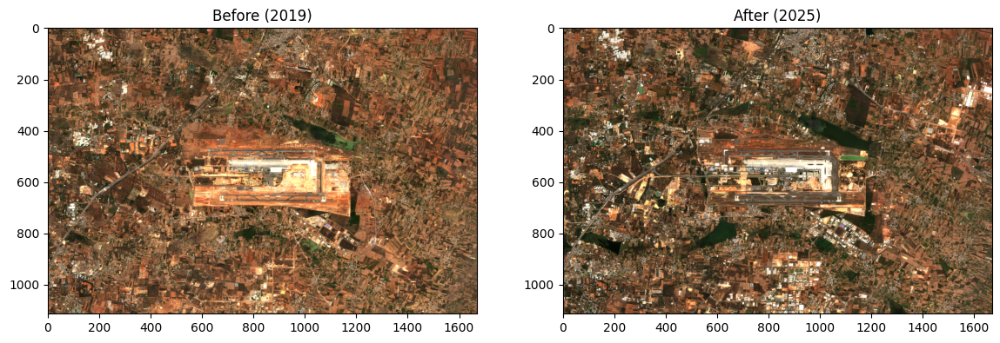

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14,7))
axes[0].imshow(before_rgb); axes[0].set_title('Before (2019)')
axes[1].imshow(after_rgb); axes[1].set_title('After (2025)')
plt.show()

In [11]:
def load_all_bands(path):
    with rasterio.open(path) as src:
        img = src.read()  # shape: (bands, height, width)
        img = np.transpose(img, (1,2,0))  # -> (height, width, bands)
        return img.astype(float), src.transform, src.crs

before_full, transform, crs = load_all_bands('/content/drive/MyDrive/hackathon/blr_before.tif')
after_full, _, _ = load_all_bands('/content/drive/MyDrive/hackathon/blr_after.tif')

print(before_full.shape)
print(after_full.shape)

(1114, 1670, 4)
(1114, 1670, 4)


In [12]:
def ndvi(img):
    red = img[:,:,2]   # B4
    nir = img[:,:,3]   # B8
    return (nir - red) / (nir + red + 1e-6)

ndvi_before = ndvi(before_full)
ndvi_after = ndvi(after_full)

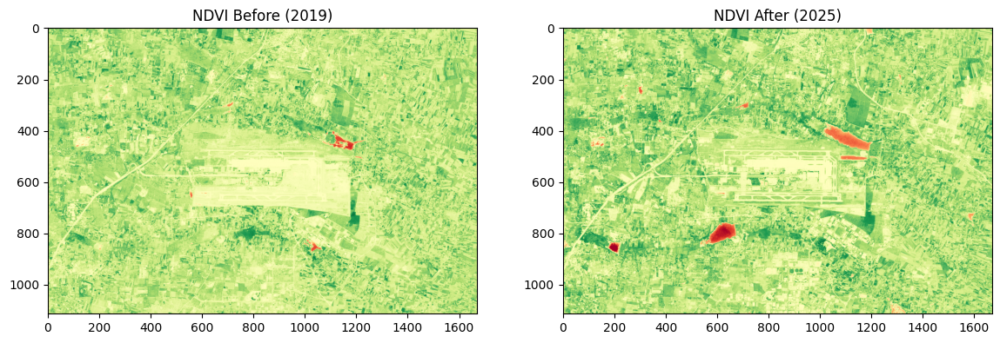

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14,7))
axes[0].imshow(ndvi_before, cmap='RdYlGn', vmin=-1, vmax=1)
axes[0].set_title('NDVI Before (2019)')
axes[1].imshow(ndvi_after, cmap='RdYlGn', vmin=-1, vmax=1)
axes[1].set_title('NDVI After (2025)')
plt.show()

In [14]:
diff = ndvi_before - ndvi_after

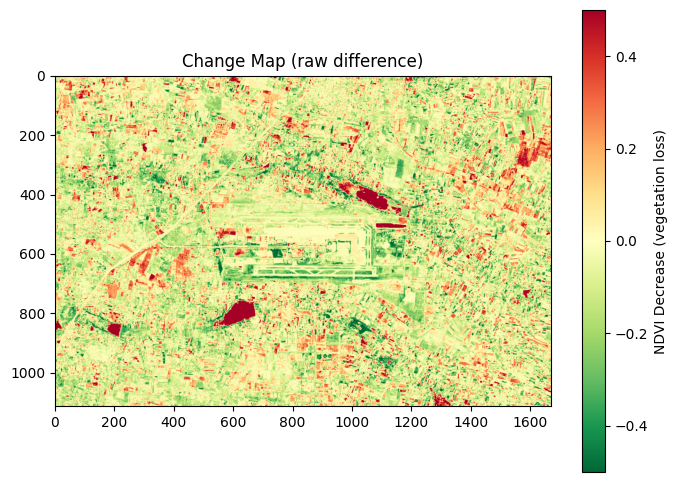

In [15]:
plt.figure(figsize=(8,6))
plt.imshow(diff, cmap='RdYlGn_r', vmin=-0.5, vmax=0.5)
plt.colorbar(label='NDVI Decrease (vegetation loss)')
plt.title('Change Map (raw difference)')
plt.show()

In [16]:
thresh = np.percentile(diff, 98)
print("Threshold used:", thresh)

change_mask = (diff > thresh).astype(np.uint8)

Threshold used: 0.4188482115719813


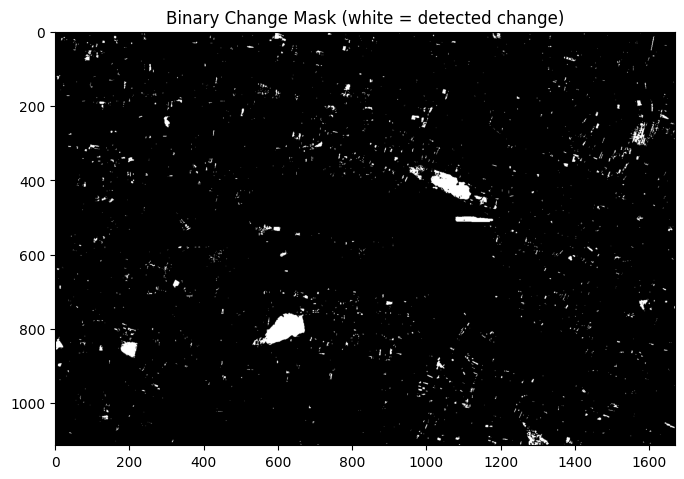

In [17]:
plt.figure(figsize=(8,6))
plt.imshow(change_mask, cmap='gray')
plt.title('Binary Change Mask (white = detected change)')
plt.show()

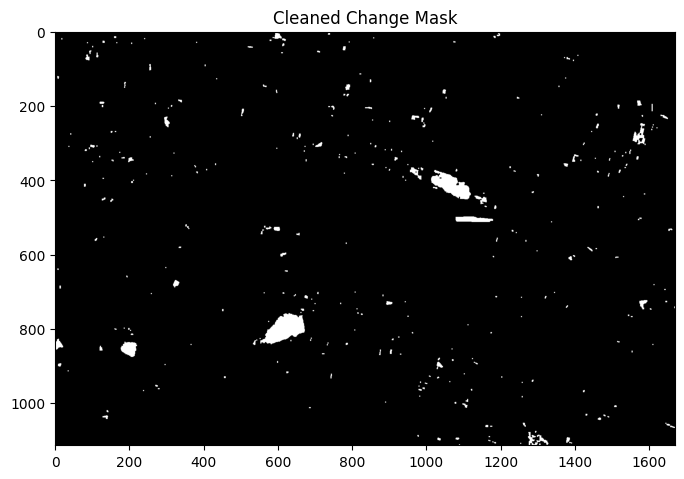

In [18]:
import cv2

kernel = np.ones((3,3), np.uint8)
mask_clean = cv2.morphologyEx(change_mask, cv2.MORPH_OPEN, kernel)   # removes small specks
mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel)  # fills small holes

plt.figure(figsize=(8,6))
plt.imshow(mask_clean, cmap='gray')
plt.title('Cleaned Change Mask')
plt.show()

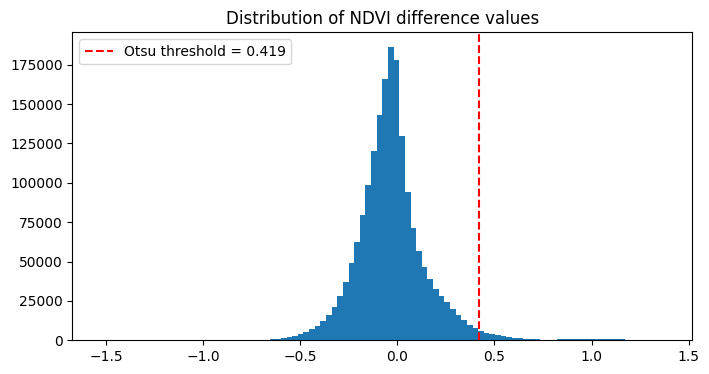

In [19]:
plt.figure(figsize=(8,4))
plt.hist(diff.flatten(), bins=100)
plt.axvline(thresh, color='red', linestyle='--', label=f'Otsu threshold = {thresh:.3f}')
plt.legend()
plt.title('Distribution of NDVI difference values')
plt.show()

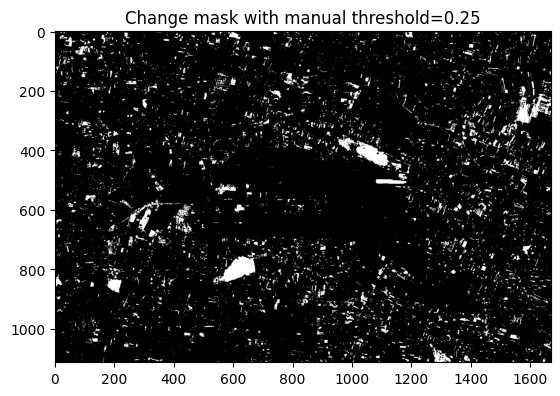

In [20]:
change_mask_strict = (diff > 0.25).astype(np.uint8)  # try a much higher fixed cutoff
plt.imshow(change_mask_strict, cmap='gray')
plt.title('Change mask with manual threshold=0.25')
plt.show()

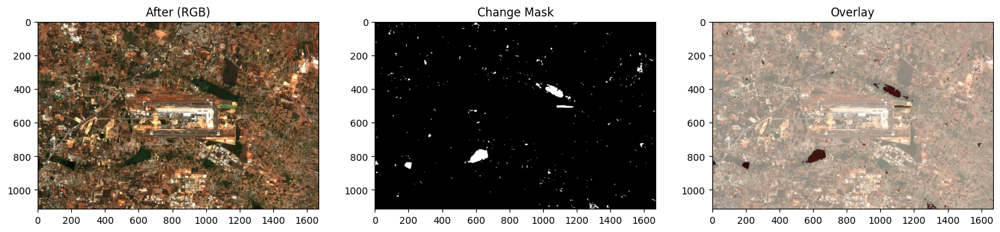

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))
axes[0].imshow(after_rgb)
axes[0].set_title('After (RGB)')
axes[1].imshow(mask_clean, cmap='gray')
axes[1].set_title('Change Mask')
axes[2].imshow(after_rgb)
axes[2].imshow(mask_clean, cmap='Reds', alpha=0.5)
axes[2].set_title('Overlay')
plt.show()

In [22]:
def ndwi(img):
    green = img[:,:,1]  # B3
    nir = img[:,:,3]    # B8
    return (green - nir) / (green + nir + 1e-6)

ndwi_before = ndwi(before_full)
ndwi_after = ndwi(after_full)

water_mask = (ndwi_before > 0) | (ndwi_after > 0)  # water in EITHER year

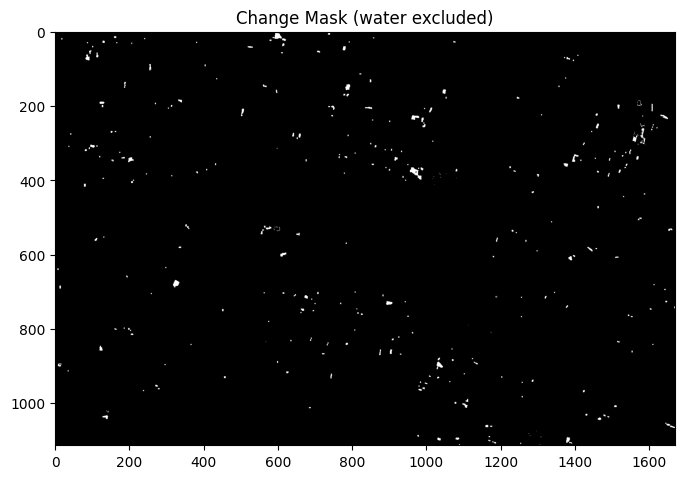

In [23]:
mask_clean_nowater = mask_clean.copy()
mask_clean_nowater[water_mask] = 0

plt.figure(figsize=(8,6))
plt.imshow(mask_clean_nowater, cmap='gray')
plt.title('Change Mask (water excluded)')
plt.show()

In [24]:
import rasterio.features
import geopandas as gpd
from shapely.geometry import shape

shapes_gen = rasterio.features.shapes(mask_clean_nowater, transform=transform)
polygons = [shape(geom) for geom, val in shapes_gen if val == 1]
gdf_changes = gpd.GeoDataFrame(geometry=polygons, crs=crs)
print(f"Total polygons found: {len(gdf_changes)}")

Total polygons found: 350


In [25]:
gdf_changes_m = gdf_changes.to_crs(epsg=32643)  # UTM zone 43N, correct for Bengaluru
gdf_changes['area_sqm'] = gdf_changes_m.geometry.area
print(gdf_changes['area_sqm'].describe())

count      350.000000
mean      2619.072950
std       3710.747084
min         96.897880
25%        872.080104
50%       1453.366921
75%       2882.592664
max      38371.565405
Name: area_sqm, dtype: float64


In [26]:
gdf_changes_filtered = gdf_changes[gdf_changes['area_sqm'] > 500].reset_index(drop=True)
print(f"Polygons after filtering: {len(gdf_changes_filtered)}")

Polygons after filtering: 301


In [27]:
import pandas as pd

gdf_changes_filtered['severity'] = pd.cut(
    gdf_changes_filtered['area_sqm'],
    bins=[0, 2000, 10000, float('inf')],
    labels=['Low', 'Medium', 'High']
)
print(gdf_changes_filtered['severity'].value_counts())

severity
Low       163
Medium    124
High       14
Name: count, dtype: int64


In [28]:
largest = gdf_changes_filtered.loc[gdf_changes_filtered['area_sqm'].idxmax()]
print(largest.geometry.bounds)
print(largest['area_sqm'])

(77.71586034350375, 13.21412799786975, 77.71864512088452, 13.217092438307345)
38371.56540534405


In [29]:
big_polys = gdf_changes_filtered[gdf_changes_filtered['area_sqm'] > 100000]
print(f"Large polygons found: {len(big_polys)}")

if len(big_polys) > 0:
    fig, ax = plt.subplots(figsize=(10,10))
    ax.imshow(after_rgb, extent=[transform[2], transform[2]+transform[0]*after_rgb.shape[1],
                                   transform[5]+transform[4]*after_rgb.shape[0], transform[5]])
    big_polys.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2)
    plt.title('Large polygons on After image')
    plt.show()
else:
    print("No large polygons remain — likely means water false-positive was removed.")

Large polygons found: 0
No large polygons remain — likely means water false-positive was removed.


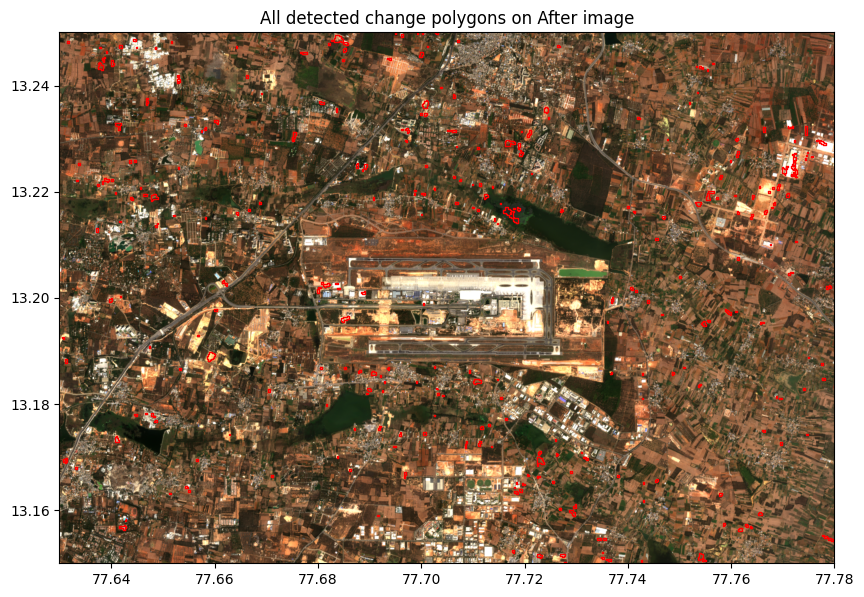

In [30]:
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(after_rgb, extent=[transform[2], transform[2]+transform[0]*after_rgb.shape[1],
                               transform[5]+transform[4]*after_rgb.shape[0], transform[5]])
gdf_changes_filtered.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1)
plt.title('All detected change polygons on After image')
plt.show()

In [31]:
from shapely.geometry import Point, Polygon, LineString
from shapely.ops import unary_union
import geopandas as gpd

# Approximate runway centerline coordinates (VOBL, both runways roughly parallel, E-W oriented)
# Runway 09R/27L (northern), Runway 09L/27R (southern) - approx thresholds
rwy_09R = (77.6810, 13.2010)
rwy_27L = (77.7330, 13.2010)
rwy_09L = (77.6810, 13.1950)
rwy_27R = (77.7330, 13.1950)

runway_09R_27L = LineString([rwy_09R, rwy_27L])
runway_09L_27R = LineString([rwy_09L, rwy_27R])

airport_center = Point(77.7064, 13.1989)

In [32]:
# Horizontal surface: circle around airport, radius per ICAO (using 4km as reasonable approx for Code 4 airport)
horizontal_surface = airport_center.buffer(4/111)  # ~4km in degrees

In [33]:
conical_outer = airport_center.buffer(6/111)  # ~6km outer boundary
conical_surface = conical_outer.difference(horizontal_surface)  # ring shape

In [34]:
def approach_surface(threshold_lon, threshold_lat, direction_lon, direction_lat, length_km=15, near_width_km=0.3, far_width_km=3):
    # direction is unit vector pointing away from runway (extended centerline direction)
    length_deg = length_km / 111
    near_w = near_width_km / 111 / 2
    far_w = far_width_km / 111 / 2

    end_lon = threshold_lon + direction_lon * length_deg
    end_lat = threshold_lat + direction_lat * length_deg

    # perpendicular direction
    perp_lon, perp_lat = -direction_lat, direction_lon

    p1 = (threshold_lon + perp_lon*near_w, threshold_lat + perp_lat*near_w)
    p2 = (threshold_lon - perp_lon*near_w, threshold_lat - perp_lat*near_w)
    p3 = (end_lon - perp_lon*far_w, end_lat - perp_lat*far_w)
    p4 = (end_lon + perp_lon*far_w, end_lat + perp_lat*far_w)

    return Polygon([p1, p2, p3, p4])

# Approach surfaces extending east and west from each runway end
approach_west = approach_surface(77.6810, 13.1980, -1, 0)
approach_east = approach_surface(77.7330, 13.1980, 1, 0)

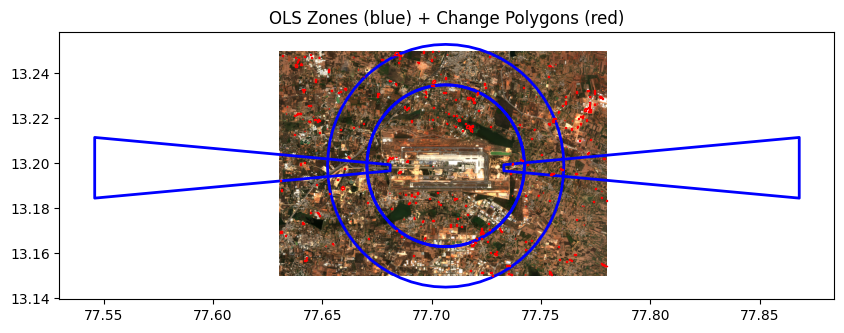

In [35]:
gdf_ols = gpd.GeoDataFrame({
    'zone_type': ['Horizontal', 'Conical', 'Approach_West', 'Approach_East'],
    'geometry': [horizontal_surface, conical_surface, approach_west, approach_east]
}, crs='EPSG:4326')

fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(after_rgb, extent=[transform[2], transform[2]+transform[0]*after_rgb.shape[1],
                               transform[5]+transform[4]*after_rgb.shape[0], transform[5]])
gdf_ols.plot(ax=ax, facecolor='none', edgecolor='blue', linewidth=2)
gdf_changes_filtered.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1)
plt.title('OLS Zones (blue) + Change Polygons (red)')
plt.show()

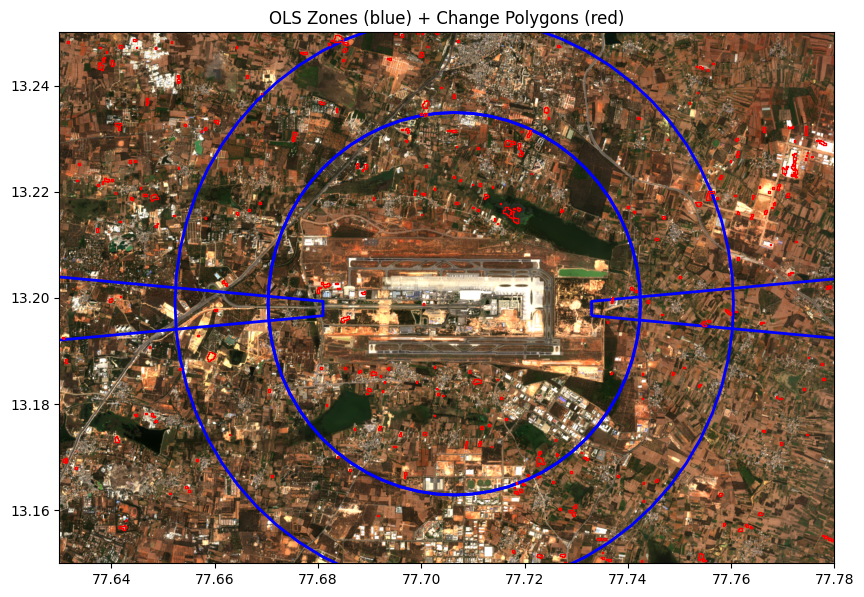

In [36]:
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(after_rgb, extent=[transform[2], transform[2]+transform[0]*after_rgb.shape[1],
                               transform[5]+transform[4]*after_rgb.shape[0], transform[5]])
gdf_ols.plot(ax=ax, facecolor='none', edgecolor='blue', linewidth=2)
gdf_changes_filtered.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1)

# Lock the view to your actual image bounds, ignore the OLS zones extending past it
ax.set_xlim(transform[2], transform[2]+transform[0]*after_rgb.shape[1])
ax.set_ylim(transform[5]+transform[4]*after_rgb.shape[0], transform[5])
plt.title('OLS Zones (blue) + Change Polygons (red)')
plt.show()

In [37]:
gdf_ols.to_file('/content/drive/MyDrive/hackathon/ols_zones.geojson', driver='GeoJSON')
print("Saved OLS zones.")

Saved OLS zones.


In [38]:
intersections = gpd.overlay(gdf_changes_filtered, gdf_ols, how='intersection')
print(f"Change polygons intersecting OLS zones: {len(intersections)}")
print(intersections['zone_type'].value_counts())

Change polygons intersecting OLS zones: 184
zone_type
Horizontal       91
Conical          80
Approach_East     9
Approach_West     4
Name: count, dtype: int64


In [39]:
# Get, for each change polygon, the list of OLS zones it intersects
zones_per_polygon = intersections.groupby(intersections.index)['zone_type'].apply(list)

In [40]:
gdf_changes_filtered['change_id'] = range(len(gdf_changes_filtered))

In [41]:
intersections = gpd.overlay(gdf_changes_filtered, gdf_ols, how='intersection')
print(intersections.columns.tolist())

['area_sqm', 'severity', 'change_id', 'zone_type', 'geometry']


In [42]:
def escalate_severity(row):
    zones_hit = intersections[intersections['change_id'] == row['change_id']]['zone_type'].tolist()
    if 'Approach_East' in zones_hit or 'Approach_West' in zones_hit:
        return 'Critical'
    elif 'Horizontal' in zones_hit:
        return 'High'
    elif 'Conical' in zones_hit:
        return 'Medium'
    else:
        return 'Low'

gdf_changes_filtered['final_severity'] = gdf_changes_filtered.apply(escalate_severity, axis=1)
print(gdf_changes_filtered['final_severity'].value_counts())

final_severity
Low         126
High         90
Medium       72
Critical     13
Name: count, dtype: int64


In [43]:
import folium

m = folium.Map(location=[13.1989, 77.7064], zoom_start=12, tiles='OpenStreetMap')

# Color mapping for severity
severity_colors = {'Critical': 'darkred', 'High': 'red', 'Medium': 'orange', 'Low': 'yellow'}

# Add OLS zones first (so they sit underneath)
folium.GeoJson(
    gdf_ols,
    style_function=lambda x: {'color': 'blue', 'weight': 2, 'fillOpacity': 0.05},
    name='OLS Zones'
).add_to(m)

# Add change polygons, colored by severity
for _, row in gdf_changes_filtered.iterrows():
    folium.GeoJson(
        row['geometry'],
        style_function=lambda x, sev=row['final_severity']: {
            'color': severity_colors[sev],
            'weight': 1,
            'fillOpacity': 0.6
        },
        tooltip=f"Severity: {row['final_severity']}<br>Area: {row['area_sqm']:.0f} sqm"
    ).add_to(m)

folium.LayerControl().add_to(m)
m.save('/content/drive/MyDrive/hackathon/alert_m')
m

In [44]:
summary = gdf_changes_filtered.groupby('final_severity').agg(
    count=('change_id', 'count'),
    total_area_sqm=('area_sqm', 'sum'),
    avg_area_sqm=('area_sqm', 'mean')
).reindex(['Critical', 'High', 'Medium', 'Low'])

print(summary)

                count  total_area_sqm  avg_area_sqm
final_severity                                     
Critical           13    39150.629064   3011.586851
High               90   280819.830744   3120.220342
Medium             72   245832.646052   3414.342306
Low               126   340891.322260   2705.486685


In [45]:
priority_alerts = gdf_changes_filtered[gdf_changes_filtered['final_severity'].isin(['Critical', 'High'])].copy()
priority_alerts_m = priority_alerts.to_crs(epsg=32643)
priority_alerts['centroid'] = priority_alerts_m.geometry.centroid.to_crs(epsg=4326)
priority_alerts['latitude'] = priority_alerts['centroid'].y
priority_alerts['longitude'] = priority_alerts['centroid'].x

report_table = priority_alerts[['change_id', 'final_severity', 'area_sqm', 'latitude', 'longitude']].sort_values('final_severity')
report_table.to_csv('/content/drive/MyDrive/hackathon/priority_alerts.csv', index=False)
print(report_table)

     change_id final_severity     area_sqm   latitude  longitude
172        172       Critical  1453.625891  13.199351  77.743933
171        171       Critical  3294.844982  13.199618  77.736913
170        170       Critical  3681.914804  13.199656  77.639901
169        169       Critical   872.032906  13.200249  77.641794
176        176       Critical  6396.164660  13.197335  77.759475
..         ...            ...          ...        ...        ...
124        124           High  2034.806472  13.217830  77.706884
119        119           High  1744.068466  13.218799  77.690752
116        116           High  6007.542718  13.219185  77.712463
111        111           High  1453.404141  13.219563  77.698747
264        264           High  1163.012665  13.165170  77.718421

[103 rows x 5 columns]


In [46]:
!pip install reportlab -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.1 MB/s eta 0:00:00


In [47]:
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Table, TableStyle, Paragraph, Spacer, Image as RLImage
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from datetime import datetime

doc_path = '/content/drive/MyDrive/hackathon/OLS_Alert_Report.pdf'
doc = SimpleDocTemplate(doc_path, pagesize=A4)
styles = getSampleStyleSheet()
elements = []

title_style = ParagraphStyle('TitleStyle', parent=styles['Title'], fontSize=18)
elements.append(Paragraph("Airport OLS Encroachment Alert Report", title_style))
elements.append(Paragraph("Kempegowda International Airport (VOBL), Bengaluru", styles['Heading2']))
elements.append(Paragraph(f"Generated: {datetime.now().strftime('%d %B %Y, %H:%M')}", styles['Normal']))
elements.append(Paragraph("Comparison period: 2019 vs 2025/26 (Sentinel-2 imagery)", styles['Normal']))
elements.append(Spacer(1, 0.7*cm))
elements.append(Paragraph("Change Detection Map", styles['Heading2']))
elements.append(RLImage('/content/drive/MyDrive/hackathon/map_static.png', width=16*cm, height=16*cm))
elements.append(Spacer(1, 0.7*cm))
elements.append(Paragraph("Executive Summary", styles['Heading2']))
total_changes = len(gdf_changes_filtered)
critical_count = (gdf_changes_filtered['final_severity']=='Critical').sum()
high_count = (gdf_changes_filtered['final_severity']=='High').sum()
summary_text = (f"A total of {total_changes} land-use change polygons were detected in the vicinity "
                f"of VOBL airport. Of these, {critical_count} fall within the airport's Approach "
                f"Surface (highest sensitivity, directly in aircraft flight paths) and {high_count} "
                f"fall within the Horizontal Surface. These require priority review for potential "
                f"unauthorized construction under AAI Obstacle Limitation Surface regulations.")
elements.append(Paragraph(summary_text, styles['Normal']))
elements.append(Spacer(1, 0.7*cm))

elements.append(Paragraph("Severity Breakdown", styles['Heading2']))
table_data = [['Severity', 'Count', 'Total Area (sqm)', 'Avg Area (sqm)']]
for sev in ['Critical', 'High', 'Medium', 'Low']:
    row = summary.loc[sev]
    table_data.append([sev, int(row['count']), f"{row['total_area_sqm']:.0f}", f"{row['avg_area_sqm']:.0f}"])

t = Table(table_data, colWidths=[3*cm, 3*cm, 4*cm, 4*cm])
t.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#2c3e50')),
    ('TEXTCOLOR', (0,0), (-1,0), colors.white),
    ('GRID', (0,0), (-1,-1), 0.5, colors.grey),
    ('FONTSIZE', (0,0), (-1,-1), 10),
    ('BACKGROUND', (0,1), (-1,1), colors.HexColor('#f8d7da')),
]))
elements.append(t)
elements.append(Spacer(1, 0.7*cm))

elements.append(Paragraph("Priority Alerts (Critical &amp; High Severity)", styles['Heading2']))
alert_table_data = [['ID', 'Severity', 'Area (sqm)', 'Latitude', 'Longitude']]
for _, row in report_table.iterrows():
    alert_table_data.append([
        row['change_id'], row['final_severity'], f"{row['area_sqm']:.0f}",
        f"{row['latitude']:.5f}", f"{row['longitude']:.5f}"
    ])

t2 = Table(alert_table_data, colWidths=[2*cm, 3*cm, 3*cm, 3.5*cm, 3.5*cm])
t2.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#2c3e50')),
    ('TEXTCOLOR', (0,0), (-1,0), colors.white),
    ('GRID', (0,0), (-1,-1), 0.5, colors.grey),
    ('FONTSIZE', (0,0), (-1,-1), 8),
]))
elements.append(t2)

doc.build(elements)
print(f"Report saved to: {doc_path}")

Report saved to: /content/drive/MyDrive/hackathon/OLS_Alert_Report.pdf


/tmp/ipykernel_708/835225663.py:13: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='upper right')
/tmp/ipykernel_708/835225663.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')


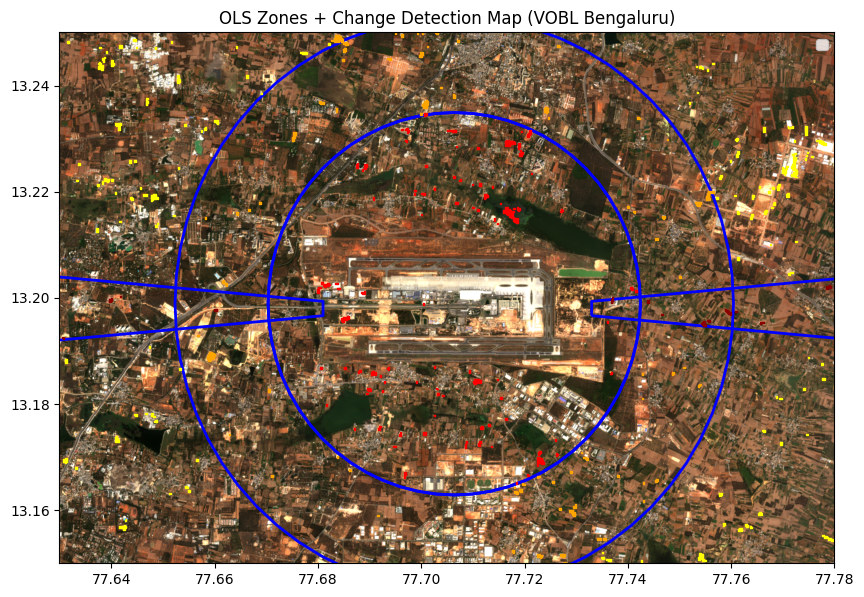

In [48]:
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(after_rgb, extent=[transform[2], transform[2]+transform[0]*after_rgb.shape[1],
                               transform[5]+transform[4]*after_rgb.shape[0], transform[5]])
gdf_ols.plot(ax=ax, facecolor='none', edgecolor='blue', linewidth=2)

severity_colors = {'Critical': 'darkred', 'High': 'red', 'Medium': 'orange', 'Low': 'yellow'}
for sev, color in severity_colors.items():
    subset = gdf_changes_filtered[gdf_changes_filtered['final_severity'] == sev]
    subset.plot(ax=ax, facecolor=color, edgecolor=color, linewidth=1, label=sev)

ax.set_xlim(transform[2], transform[2]+transform[0]*after_rgb.shape[1])
ax.set_ylim(transform[5]+transform[4]*after_rgb.shape[0], transform[5])
ax.legend(loc='upper right')
plt.title('OLS Zones + Change Detection Map (VOBL Bengaluru)')
plt.savefig('/content/drive/MyDrive/hackathon/map_static.png', dpi=150, bbox_inches='tight')
plt.show()

In [49]:
import numpy as np

np.save('/content/drive/MyDrive/hackathon/before_rgb.npy', before_rgb)
np.save('/content/drive/MyDrive/hackathon/after_rgb.npy', after_rgb)
print("Saved before_rgb and after_rgb to Drive for reuse in U-Net experiment notebook.")

Saved before_rgb and after_rgb to Drive for reuse in U-Net experiment notebook.


In [50]:
gdf_changes_filtered.to_file('/content/drive/MyDrive/hackathon/ndvi_change_polygons.geojson', driver='GeoJSON')
print("Saved full NDVI polygon set.")

Saved full NDVI polygon set.


In [51]:
import smtplib
from email.mime.multipart import MIMEMultipart
from email.mime.text import MIMEText
from email.mime.application import MIMEApplication

def send_alert_email(sender_email, app_password, receiver_email, subject, body, attachment_path=None):
    msg = MIMEMultipart()
    msg['From'] = sender_email
    msg['To'] = receiver_email
    msg['Subject'] = subject
    msg.attach(MIMEText(body, 'plain'))

    if attachment_path:
        with open(attachment_path, 'rb') as f:
            part = MIMEApplication(f.read(), Name='OLS_Alert_Report.pdf')
        part['Content-Disposition'] = f'attachment; filename="OLS_Alert_Report.pdf"'
        msg.attach(part)

    with smtplib.SMTP('smtp.gmail.com', 587) as server:
        server.starttls()
        server.login(sender_email, app_password)
        server.send_message(msg)

    print("Alert email sent successfully.")

In [66]:
critical_count = (gdf_changes_filtered['final_severity'] == 'Critical').sum()
high_count = (gdf_changes_filtered['final_severity'] == 'High').sum()

critical_list = gdf_changes_filtered[gdf_changes_filtered['final_severity'] == 'Critical']

alert_body = f"""AEROGUARD ALERT — Kempegowda International Airport (VOBL)

This is an automated alert from AeroGuard, the Satellite Change Detection System for Airport OLS Zone Encroachment Monitoring.

Summary:
- {critical_count} CRITICAL alerts detected in Approach Surface zones (highest priority)
- {high_count} HIGH severity alerts detected in Horizontal Surface zone

Critical Alert Locations (require immediate field verification):
"""

for _, row in critical_list.iterrows():
    centroid = row['geometry'].centroid
    alert_body += f"- ID {row['change_id']}: Lat {centroid.y:.5f}, Lon {centroid.x:.5f}, Area {row['area_sqm']:.0f} sqm\n"

alert_body += """

Full details are attached in the PDF report.

This is an automated message generated for demonstration purposes.
"""

print(alert_body)

AEROGUARD ALERT — Kempegowda International Airport (VOBL)

This is an automated alert from AeroGuard, the Satellite Change Detection System for Airport OLS Zone Encroachment Monitoring.

Summary:
- 13 CRITICAL alerts detected in Approach Surface zones (highest priority)
- 90 HIGH severity alerts detected in Horizontal Surface zone

Critical Alert Locations (require immediate field verification):
- ID 163: Lat 13.20206, Lon 77.77883, Area 4749 sqm
- ID 169: Lat 13.20025, Lon 77.64179, Area 872 sqm
- ID 170: Lat 13.19966, Lon 77.63990, Area 3682 sqm
- ID 171: Lat 13.19962, Lon 77.73691, Area 3295 sqm
- ID 172: Lat 13.19935, Lon 77.74393, Area 1454 sqm
- ID 174: Lat 13.19778, Lon 77.66021, Area 2519 sqm
- ID 175: Lat 13.19746, Lon 77.76096, Area 1163 sqm
- ID 176: Lat 13.19733, Lon 77.75947, Area 6396 sqm
- ID 177: Lat 13.19693, Lon 77.74663, Area 872 sqm
- ID 179: Lat 13.19568, Lon 77.75558, Area 2229 sqm
- ID 181: Lat 13.19538, Lon 77.76593, Area 2810 sqm
- ID 182: Lat 13.19513, Lon 77.

In [76]:
from google.colab import userdata

# Retrieve the password securely from Colab Secrets
try:
    secret_password = userdata.get('MY_APP_PASSWORD')

    send_alert_email(
        sender_email='akilansu47@gmail.com',
        app_password=secret_password,
        receiver_email='inairportauthority@gmail.com',
        subject=f'URGENT: {critical_count} Critical OLS Encroachment Alerts — VOBL Airport',
        body=alert_body,
        attachment_path='/content/drive/MyDrive/hackathon/OLS_Alert_Report.pdf'
    )
except userdata.SecretNotFoundError:
    print("Error: Please add 'MY_APP_PASSWORD' to the Colab Secrets menu (key icon) before running.")

Alert email sent successfully.


In [70]:
%%writefile app.py
import streamlit as st
import geopandas as gpd
import pandas as pd
import rasterio
import numpy as np
from streamlit_folium import st_folium
import folium
import smtplib
from email.mime.multipart import MIMEMultipart
from email.mime.text import MIMEText
from email.mime.application import MIMEApplication

st.set_page_config(page_title="AeroGuard", layout="wide", page_icon="🛰️")
st.title("🛰️ AeroGuard")
st.subheader("Airport OLS Encroachment Monitoring System — Kempegowda International Airport (VOBL), Bengaluru")

DATA_DIR = "/content/drive/MyDrive/hackathon"

st.title("🛰️ Airport OLS Encroachment Monitoring System")
st.subheader("Kempegowda International Airport (VOBL), Bengaluru")
st.caption("🎯 Automated satellite monitoring flags priority encroachment zones in minutes — work that would otherwise require days of manual field inspection across a 15km radius.")

# Load data
gdf_changes = gpd.read_file(f"{DATA_DIR}/ndvi_change_polygons.geojson")
gdf_ols = gpd.read_file(f"{DATA_DIR}/ols_zones.geojson")
priority_alerts = pd.read_csv(f"{DATA_DIR}/priority_alerts.csv")

# ---- Summary metrics ----
col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Changes Detected", len(gdf_changes))
col2.metric("Critical Alerts", (gdf_changes['final_severity']=='Critical').sum())
col3.metric("High Severity", (gdf_changes['final_severity']=='High').sum())
col4.metric("Total Affected Area (sqm)", f"{gdf_changes['area_sqm'].sum():,.0f}")

chart_col, _ = st.columns([1,2])
with chart_col:
    severity_order = ['Critical','High','Medium','Low']
    severity_counts = gdf_changes['final_severity'].value_counts().reindex(severity_order).fillna(0)
    st.bar_chart(severity_counts)

st.divider()

# ---- Tabs for organization ----
tab1, tab2, tab3, tab4 = st.tabs(["🗺️ Live Map", "🖼️ Before/After Comparison", "📧 Send Alert", "🧠 NDVI vs U-Net"])

with tab1:
    map_col, table_col = st.columns([2,1])

    with map_col:
        st.markdown("### OLS Zones + Detected Changes")
        st.caption("🔵 Blue = OLS Zones | 🔴 Dark Red = Critical | 🟠 Red = High | 🟡 Orange = Medium | 🟢 Yellow = Low")

        m = folium.Map(location=[13.1989, 77.7064], zoom_start=13, tiles='OpenStreetMap')

        folium.GeoJson(
            gdf_ols,
            style_function=lambda x: {'color':'blue','weight':2,'fillOpacity':0.05},
            name='OLS Zones'
        ).add_to(m)

        severity_colors = {'Critical':'darkred','High':'red','Medium':'orange','Low':'gold'}
        for _, row in gdf_changes.iterrows():
            folium.GeoJson(
                row['geometry'],
                style_function=lambda x, sev=row['final_severity']: {
                    'color': severity_colors.get(sev,'gray'), 'weight':1, 'fillOpacity':0.6
                },
                tooltip=f"ID {row['change_id']} | Severity: {row['final_severity']} | Area: {row['area_sqm']:.0f} sqm"
            ).add_to(m)

        folium.LayerControl().add_to(m)
        st_folium(m, width=800, height=550)

    with table_col:
        st.markdown("### Priority Alerts")
        severity_filter = st.multiselect("Filter by severity", ['Critical','High','Medium','Low'], default=['Critical','High'])
        filtered = gdf_changes[gdf_changes['final_severity'].isin(severity_filter)]
        st.dataframe(filtered[['change_id','final_severity','area_sqm']].sort_values('final_severity'), height=490)

with tab2:
    st.markdown("### Satellite Imagery Comparison (2019 vs 2025/26)")

    def load_rgb(path):
        with rasterio.open(path) as src:
            img = src.read([3,2,1])
            img = np.transpose(img, (1,2,0))
            img = np.clip(img / 3000, 0, 1)
            return img

    before_rgb = load_rgb(f"{DATA_DIR}/blr_before.tif")
    after_rgb = load_rgb(f"{DATA_DIR}/blr_after.tif")

    view_mode = st.radio("View mode", ["Side by side", "Slider comparison"], horizontal=True)

    if view_mode == "Side by side":
        c1, c2 = st.columns(2)
        c1.image(before_rgb, caption="2019 (Before)", use_container_width=True)
        c2.image(after_rgb, caption="2025/26 (After)", use_container_width=True)
    else:
        slider_val = st.slider("Drag to compare", 0, 100, 50)
        blend = (before_rgb * (1 - slider_val/100) + after_rgb * (slider_val/100))
        st.image(blend, caption=f"Blend: {100-slider_val}% Before / {slider_val}% After", use_container_width=True)

    st.image(f"{DATA_DIR}/map_static.png", caption="Full Change Detection Map", use_container_width=True)

with tab3:
    st.markdown("### Send Alert to Airport Officials")
    st.warning(f"⚠️ {(gdf_changes['final_severity']=='Critical').sum()} Critical alerts are pending review.")

    with st.form("alert_form"):
        sender_email = st.text_input("Sender Gmail address")
        app_password = st.text_input("Gmail App Password", type="password")
        receiver_email = st.text_input("Recipient email (Airport Official)")
        submitted = st.form_submit_button("🚨 Send Alert Now")

        if submitted:
            critical_list = gdf_changes[gdf_changes['final_severity']=='Critical']
            alert_body = f"""AIRPORT OLS ENCROACHMENT ALERT — Kempegowda International Airport (VOBL)

This is an automated alert from the Satellite Change Detection System.

Summary:
- {len(critical_list)} CRITICAL alerts detected in Approach Surface zones (highest priority)
- {(gdf_changes['final_severity']=='High').sum()} HIGH severity alerts detected

Critical Alert Locations:
"""
            for _, row in critical_list.iterrows():
                c = row['geometry'].centroid
                alert_body += f"- ID {row['change_id']}: Lat {c.y:.5f}, Lon {c.x:.5f}, Area {row['area_sqm']:.0f} sqm\n"
            alert_body += "\nFull details attached.\n"

            try:
                msg = MIMEMultipart()
                msg['From'] = sender_email
                msg['To'] = receiver_email
                msg['Subject'] = f"URGENT: {len(critical_list)} Critical OLS Alerts — VOBL Airport"
                msg.attach(MIMEText(alert_body, 'plain'))

                with open(f"{DATA_DIR}/OLS_Alert_Report.pdf", 'rb') as f:
                    part = MIMEApplication(f.read(), Name='OLS_Alert_Report.pdf')
                part['Content-Disposition'] = 'attachment; filename="OLS_Alert_Report.pdf"'
                msg.attach(part)

                with smtplib.SMTP('smtp.gmail.com', 587) as server:
                    server.starttls()
                    server.login(sender_email, app_password)
                    server.send_message(msg)

                st.success("✅ Alert sent successfully!")
            except Exception as e:
                st.error(f"Failed to send: {e}")
with tab4:
    st.markdown("### Methodology Comparison: NDVI Differencing vs U-Net Deep Learning")
    st.caption("Two independent detection methods run on the same imagery — NDVI differencing is our primary, validated method; U-Net is a deep learning approach trained on the LEVIR-CD benchmark dataset (Texas, USA) and applied here via domain transfer.")

    gdf_unet = gpd.read_file(f"{DATA_DIR}/unet_change_polygons.geojson")

    mcol1, mcol2 = st.columns(2)
    mcol1.metric("NDVI Polygons Detected", len(gdf_changes))
    mcol2.metric("U-Net Polygons Detected", len(gdf_unet))

    comp_col1, comp_col2 = st.columns(2)

    with comp_col1:
        st.markdown("**NDVI Differencing**")
        m1 = folium.Map(location=[13.1989, 77.7064], zoom_start=13)
        for _, row in gdf_changes.iterrows():
            folium.GeoJson(row['geometry'], style_function=lambda x: {'color':'red','weight':1,'fillOpacity':0.5}).add_to(m1)
        st_folium(m1, width=550, height=450, key="ndvi_map")

    with comp_col2:
        st.markdown("**U-Net Detection**")
        m2 = folium.Map(location=[13.1989, 77.7064], zoom_start=13)
        for _, row in gdf_unet.iterrows():
            folium.GeoJson(row['geometry'], style_function=lambda x: {'color':'cyan','weight':1,'fillOpacity':0.5}).add_to(m2)
        st_folium(m2, width=550, height=450, key="unet_map")

    st.info("💡 NDVI differencing produces precise, small-scale detections validated against OLS zones with severity scoring. U-Net captures broader neighborhood-level development patterns, demonstrating deep learning feasibility for future fine-tuning on India-specific imagery.")
st.divider()
st.markdown("### Downloads")
dl1, dl2 = st.columns(2)
with dl1:
    with open(f"{DATA_DIR}/OLS_Alert_Report.pdf", "rb") as f:
        st.download_button("📄 Download Full PDF Report", f, file_name="OLS_Alert_Report.pdf")
with dl2:
    st.download_button("📊 Download Priority Alerts CSV", priority_alerts.to_csv(index=False), file_name="priority_alerts.csv")

Overwriting app.py


In [56]:
!pip install streamlit streamlit-folium -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.7/536.7 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.3 MB/s eta 0:00:00


In [57]:
!npm install -g localtunnel -q

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏

In [71]:
!pkill -f streamlit
!nohup streamlit run app.py --server.port 8501 &>/content/logs.txt &

In [59]:
import time
time.sleep(8)
!cat /content/logs.txt



2026-07-30 22:41:23.446 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.106.11.212:8501



In [60]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹your url is: https://ripe-walls-share.loca.lt
^C


In [61]:
!pip install pyngrok -q

In [72]:
from pyngrok import ngrok

ngrok.set_auth_token("3HE9YeIDSlDEPTwecjkbN3sE3x7_3Y8mNmAhfbzxs46ssmiHb")
public_url = ngrok.connect(8501)
print("Your app is live at:", public_url)

Your app is live at: NgrokTunnel: "https://confider-doctrine-untangled.ngrok-free.dev" -> "http://localhost:8501"


In [63]:
import shutil
shutil.copy(
    '/content/drive/MyDrive/hackathon/unet_experiment/unet_change_polygons.geojson',
    '/content/drive/MyDrive/hackathon/unet_change_polygons.geojson'
)
print("Copied U-Net polygons to main hackathon folder.")

Copied U-Net polygons to main hackathon folder.


In [64]:
import random

sample_ids = random.sample(list(gdf_changes_filtered['change_id']), min(15, len(gdf_changes_filtered)))
print("Manually verify these polygon IDs against the after_rgb image:")
print(sample_ids)

Manually verify these polygon IDs against the after_rgb image:
[62, 159, 28, 110, 96, 238, 85, 231, 268, 148, 232, 50, 98, 207, 161]


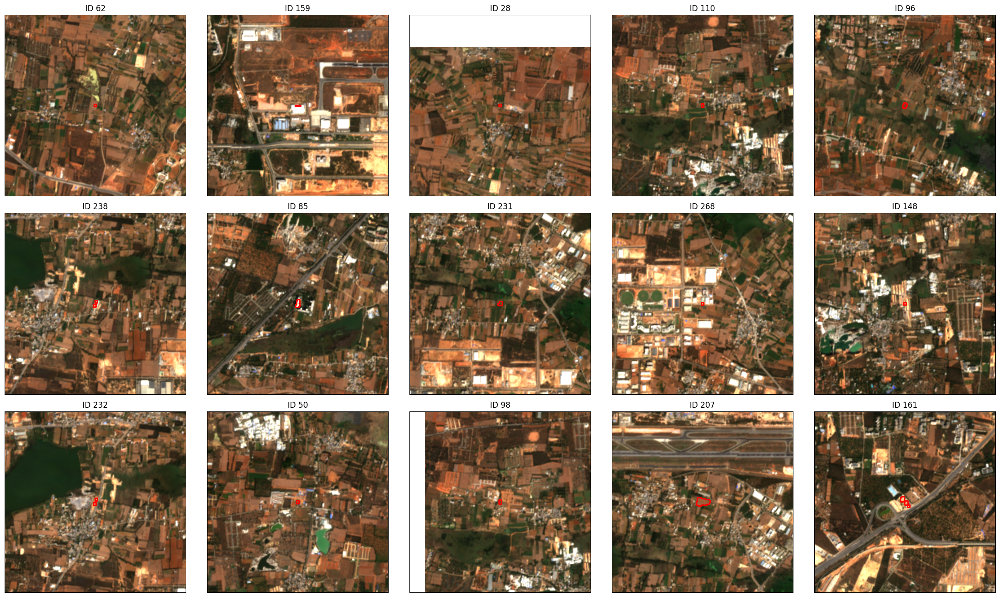

In [65]:
fig, axes = plt.subplots(3, 5, figsize=(22, 13))
extent = [transform[2], transform[2]+transform[0]*after_rgb.shape[1],
          transform[5]+transform[4]*after_rgb.shape[0], transform[5]]

for ax, cid in zip(axes.flat, sample_ids):
    row = gdf_changes_filtered[gdf_changes_filtered['change_id'] == cid].iloc[0]
    centroid = row.geometry.centroid
    ax.imshow(after_rgb, extent=extent)
    ax.set_xlim(centroid.x - 0.01, centroid.x + 0.01)
    ax.set_ylim(centroid.y - 0.01, centroid.y + 0.01)
    gpd.GeoSeries([row.geometry]).plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2)
    ax.set_title(f"ID {cid}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()